# Lecture 3: Public administration

The third model adds a government to the three-good economy of the second notebook. The government collects a direct tax on household income and an indirect tax on each good, and spends all of its revenue on goods. The indirect tax drives a wedge between the price producers receive and the price buyers pay, so each good now has two prices. There is still no saving, investment or trade.

:::{admonition} Watch the lectures
:class: tip

- 📺 Lecture: [Computable General Equilibrium model with public administration](https://www.youtube.com/watch?v=1FWLA-nBrls)
- ✅ Correction: [General Equilibrium models with Public Administration - Correction](https://www.youtube.com/watch?v=fVJ_BygvcEg)
- 🎓 Full course playlist: [Antoine Bouet's CGE lectures](https://www.youtube.com/playlist?list=PLfV47vAW_jrc57x1O36Pz9vol86f0YUXW)
:::

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cge_modeling as cm

## The economy

Production is unchanged from the second notebook. Each sector combines value added and an intermediate bundle in fixed proportions, value added is Cobb-Douglas in capital and labor, and the bundle combines the three goods in fixed proportions.

The government, which the course calls the public administration, adds three flows:

- A direct tax at rate $itr$ on household income $INC$. Households spend their disposable income $DISP\_INC = (1 - itr) \cdot INC$.
- An indirect tax at rate $\tau_i$ on good $i$. Producers receive $PY_i$ per unit and buyers pay $P_i = (1 + \tau_i) \cdot PY_i$.
- Purchases of goods $CG_i$. The government spends its whole budget $BUDG\_EXP$, and Cobb-Douglas shares $\alpha^G_i$ split it across the three goods.

The government budget is balanced: tax revenue equals spending.

### Variables

The variables of the second notebook carry over. Four are new: the producer price $PY_i$, disposable income, the government budget, and government purchases $CG_i$.

In [2]:
sectors = ["Agr", "Ind", "Serv"]
mod = cm.CGEModel(coords={"i": sectors, "j": sectors})

with mod:
    Y = cm.Variable("Y", dims="i", description="Output of sector <dim:i>")
    VA = cm.Variable("VA", dims="i", description="Value added in sector <dim:i>")
    IC = cm.Variable("IC", dims="i", description="Intermediate bundle used by sector <dim:i>")
    CIJ = cm.Variable("CIJ", dims=("i", "j"), description="Good <dim:i> used by sector <dim:j>")
    KD = cm.Variable("KD", dims="i", description="Capital demand of sector <dim:i>")
    LD = cm.Variable("LD", dims="i", description="Labor demand of sector <dim:i>")
    P = cm.Variable("P", dims="i", description="Consumer price of good <dim:i>")
    PY = cm.Variable("PY", dims="i", description="Producer price of good <dim:i>")
    PVA = cm.Variable("PVA", dims="i", description="Price of value added in sector <dim:i>")
    PIC = cm.Variable("PIC", dims="i", description="Price of the intermediate bundle in sector <dim:i>")
    W = cm.Variable("W", description="Wage")
    R = cm.Variable("R", description="Return to capital")
    INC = cm.Variable("INC", description="Gross income of households")
    DISP_INC = cm.Variable("DISP_INC",
                           latex_name=r"\mathrm{DISP\_INC}",
                           description="Disposable income of households")
    C = cm.Variable("C", dims="i", description="Household consumption of good <dim:i>")
    U = cm.Variable("U", description="Utility of households")
    BUDG_EXP = cm.Variable("BUDG_EXP",
                           latex_name=r"\mathrm{BUDG\_EXP}",
                           description="Government budget")
    CG = cm.Variable("CG", dims="i", description="Government purchases of good <dim:i>")
    Leon = cm.Variable("Leon", description="Walras check variable")

mod.summary("variables")

<IPython.core.display.Latex object>

### Parameters

The new parameters are the two tax rates and the government's spending shares. The numeraire is again the consumer price of agriculture.

In [3]:
with mod:
    alpha = cm.Parameter("alpha", dims="i", description="Capital share of value added in sector <dim:i>")
    A = cm.Parameter("A", dims="i", description="Productivity in sector <dim:i>")
    psi_VA = cm.Parameter("psi_VA", dims="i", description="Value added per unit of output in sector <dim:i>")
    psi_IC = cm.Parameter("psi_IC", dims="i", description="Intermediate bundle per unit of output in sector <dim:i>")
    psi_IJC = cm.Parameter("psi_IJC",
                           dims=("i", "j"),
                           description="Good <dim:i> per unit of the intermediate bundle of sector <dim:j>")
    gamma = cm.Parameter("gamma", dims="i", description="Household budget share of good <dim:i>")
    alpha_g = cm.Parameter("alpha_g",
                           dims="i",
                           latex_name=r"\alpha^G",
                           description="Government budget share of good <dim:i>")
    itr = cm.Parameter("itr", description="Income tax rate")
    tau = cm.Parameter("tau", dims="i", description="Indirect tax rate on good <dim:i>")
    LS = cm.Parameter("LS", description="Labor supply")
    KS = cm.Parameter("KS", description="Capital supply")
    P_Agr = cm.Parameter("P_Agr", latex_name=r"\bar{P}_{Agr}", description="Price of agriculture, the numeraire")

mod.summary("parameters")

<IPython.core.display.Latex object>

### Equations

Three equations change from the second notebook. Zero profit now values output at the producer price $PY_i$, because the firm keeps only the producer price and the tax goes to the government. Households spend disposable income instead of gross income. Goods market clearing adds government purchases to the demand for each good.

The other three are new. The tax wedge links the two prices of each good. The government budget adds income tax revenue and indirect tax revenue, $\tau_i \cdot PY_i \cdot Y_i$. Government demand gives each good a fixed share of the budget. Intermediate inputs and both kinds of final demand pay the consumer price $P_i$.

In [4]:
with mod:
    cm.Equation("Tax wedge", PY * (1 + tau), P)
    cm.Equation("Value added demand", VA, psi_VA * Y)
    cm.Equation("Intermediate bundle demand", IC, psi_IC * Y)
    cm.Equation("Zero profit", PY * Y, PVA * VA + PIC * IC)
    cm.Equation("Value added production", VA, A * KD**alpha * LD ** (1 - alpha))
    cm.Equation("Capital demand", R * KD, alpha * PVA * VA)
    cm.Equation("Labor demand", W * LD, (1 - alpha) * PVA * VA)
    cm.Equation("Intermediate bundle price", (PIC * IC).rename(i="j"), (P * CIJ).sum("i"))
    cm.Equation("Intermediate input demand", CIJ, psi_IJC * IC.rename(i="j"))
    cm.Equation("Income", INC, W * LS + R * KS)
    cm.Equation("Disposable income", DISP_INC, (1 - itr) * INC)
    cm.Equation("Consumption", P * C, gamma * DISP_INC)
    cm.Equation("Utility", U, (C**gamma).prod())
    cm.Equation("Government budget", BUDG_EXP, itr * INC + (tau * PY * Y).sum())
    cm.Equation("Government demand", P * CG, alpha_g * BUDG_EXP)
    cm.Equation("Labor market clearing", LS, LD.sum() + Leon)
    cm.Equation("Capital market clearing", KS, KD.sum())
    cm.Equation("Goods market clearing", Y, C + CG + CIJ.sum("j"))
    cm.Equation("Numeraire", P.sel(i="Agr"), P_Agr)

mod.equation_table()

<IPython.core.display.Latex object>

In [5]:
mod.compile();

Compiling a model with 49 equations, 49 variables, 34 parameters


The model has 49 equations in 49 variables, eight more of each than the second notebook: three producer prices, three government purchases, disposable income and the government budget.

## Data

The correction uses a compact SAM with a government account `Gvt`. The `Gvt` row holds the government's revenue: the household pays 3700 in income tax, and the three goods columns pay 100, 220 and 180 in indirect tax. The `Gvt` column holds its purchases of the three goods, 4200 in total, so the budget balances. The lecture's SAM also routes capital income through an enterprise account, which passes all of it on to households. The compact SAM drops that account.

Every entry is valued at consumer prices. A goods column total, such as 5100 for agriculture, is the value of output including the indirect tax.

In [6]:
accounts = ["LD", "KD", "HHld", "Gvt", *sectors]
sam = pd.DataFrame(0.0, index=accounts, columns=accounts)
sam.loc["LD", sectors] = [1300.0, 1900.0, 4000.0]
sam.loc["KD", sectors] = [200.0, 2100.0, 500.0]
sam.loc["HHld", ["LD", "KD"]] = [7200.0, 2800.0]
sam.loc["Gvt", ["HHld", *sectors]] = [3700.0, 100.0, 220.0, 180.0]
sam.loc[sectors, "HHld"] = [1700.0, 1200.0, 3400.0]
sam.loc[sectors, "Gvt"] = [400.0, 1500.0, 2300.0]
sam.loc[sectors, sectors] = [[1000.0, 1000.0, 1000.0],
                             [2010.0, 3510.0, 3000.0],
                             [490.0, 2490.0, 1000.0]]

assert np.allclose(sam.sum(axis=0), sam.sum(axis=1))
sam

,LD,KD,HHld,Gvt,Agr,Ind,Serv
LD,0.0,0.0,0.0,0.0,1300.0,1900.0,4000.0
KD,0.0,0.0,0.0,0.0,200.0,2100.0,500.0
HHld,7200.0,2800.0,0.0,0.0,0.0,0.0,0.0
Gvt,0.0,0.0,3700.0,0.0,100.0,220.0,180.0
Agr,0.0,0.0,1700.0,400.0,1000.0,1000.0,1000.0
Ind,0.0,0.0,1200.0,1500.0,2010.0,3510.0,3000.0
Serv,0.0,0.0,3400.0,2300.0,490.0,2490.0,1000.0


## Calibration

The SAM records values at consumer prices, and with an indirect tax the producer and consumer prices of a good cannot both be 1. The course normalizes the producer prices, $PY_{0,i} = 1$, along with the wage, the return to capital and the two composite prices. The consumer price is then $P_{0,i} = 1 + \tau_i$, and every quantity of a good is its SAM value divided by $P_{0,i}$.

The tax rate comes from the goods column. Its total $P_{0,i} \cdot Y_{0,i}$ is producer revenue plus the tax $INDTAX_i$ in the `Gvt` row, so

$$\tau_i = \frac{INDTAX_i}{PY_{0,i} \cdot Y_{0,i}} = \frac{INDTAX_i}{P_{0,i} \cdot Y_{0,i} - INDTAX_i}.$$

The income tax rate is the tax paid divided by gross income. The household budget shares $\gamma_i$ are shares of disposable income, and the government shares $\alpha^G_i$ are shares of its budget. The numeraire keeps agriculture's consumer price at its benchmark value $P_{0,Agr} = 1.02$, which is the first benchmark price in the series that is not 1.

In [7]:
def calibrate_model(mod, *, LD, KD, CIJ, C, CG, INDTAX, income_tax):
    PY = np.ones(len(sectors))
    PVA = np.ones(len(sectors))
    PIC = np.ones(len(sectors))
    W = 1.0
    R = 1.0

    output_value = LD + KD + CIJ.sum(axis=0) + INDTAX
    tau = INDTAX / (output_value - INDTAX)
    P = PY * (1 + tau)

    CIJ = CIJ / P[:, None]
    C = C / P
    CG = CG / P
    Y = output_value / P

    LS = LD.sum()
    KS = KD.sum()
    VA = (W * LD + R * KD) / PVA
    alpha = R * KD / (PVA * VA)
    A = VA / (KD**alpha * LD ** (1 - alpha))
    IC = (P[:, None] * CIJ).sum(axis=0) / PIC

    psi_VA = VA / Y
    psi_IC = IC / Y
    psi_IJC = CIJ / IC[None, :]

    INC = W * LS + R * KS
    itr = income_tax / INC
    DISP_INC = (1 - itr) * INC
    gamma = P * C / DISP_INC
    U = np.prod(C**gamma)
    BUDG_EXP = (P * CG).sum()
    alpha_g = P * CG / BUDG_EXP

    Leon = LS - LD.sum()
    P_Agr = P[sectors.index("Agr")]

    return mod.finalize_calibration()


calibrated_values = calibrate_model(mod,
                                    LD=sam.loc["LD", sectors].values,
                                    KD=sam.loc["KD", sectors].values,
                                    CIJ=sam.loc[sectors, sectors].values,
                                    C=sam.loc[sectors, "HHld"].values,
                                    CG=sam.loc[sectors, "Gvt"].values,
                                    INDTAX=sam.loc["Gvt", sectors].values,
                                    income_tax=sam.loc["Gvt", "HHld"])

In [8]:
pd.DataFrame({name: calibrated_values[name] for name in ["tau", "P", "Y", "C", "CG", "gamma", "alpha_g"]},
             index=sectors).round(4)

,tau,P,Y,C,CG,gamma,alpha_g
Agr,0.0200,1.0200,5000.0,1666.6667,392.1569,0.2698,0.0952
Ind,0.0200,1.0200,11000.0,1176.4706,1470.5882,0.1905,0.3571
Serv,0.0189,1.0189,9500.0,3336.7769,2257.2314,0.5397,0.5476


In [9]:
mod.check_for_equilibrium(calibrated_values)

Equilibrium found! Total squared error: 0.000000


## Cutting the income tax rate

The lecture's exercise cuts the income tax rate by 5 percentage points. The correction instead multiplies the rate by 0.9, which cuts it from 0.37 to 0.333, and only that experiment is solved in the video. This section reproduces the correction, and the next section covers the whole range of rates, the exercise's 0.32 included.

In [10]:
tax_cut = mod.simulate(initial_state=calibrated_values,
                       final_delta_pct={"itr": 0.9})
assert tax_cut["optim_res"].success

Progress               Elapsed   Residual     ||Jᵀf||      Step         
 ──────────────────────────────────────────────────────────────────────────────────────── 
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:02   0.00000977   0.00929579   10000/10000  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000003       3/    3

The correction reports the same statistics as the second notebook:

| | Agr | Ind | Serv |
|---|---|---|---|
| $Y$ growth (%) | 1.446 | -0.441 | -0.091 |
| $C$ growth (%) | 5.871 | 5.924 | 5.851 |
| $P$ growth (%) | 0 | -0.050 | 0.019 |

and growth of 0.116% in the wage, -0.305% in the return to capital and -0.002% in income. The correction leaves out the factor 100 in the Fisher consumer price index and reports $PIndC = 1.000$. The functions below keep the factor 100, as in the second notebook.

In [11]:
def growth(result, name):
    variables = result["optimizer"]["variables"]
    initial = variables[name].isel(step=0).values
    final = variables[name].isel(step=-1).values
    return 100 * (final / initial - 1)


def sector_growth(result, names):
    return pd.DataFrame({f"{name} growth (%)": growth(result, name) for name in names},
                        index=sectors).T


def aggregate_growth(result):
    variables = result["optimizer"]["variables"]
    benchmark_prices = variables["P"].isel(step=0).values
    benchmark_consumption = variables["C"].isel(step=0).values
    prices = variables["P"].isel(step=-1).values
    consumption = variables["C"].isel(step=-1).values

    laspeyres = (prices * benchmark_consumption).sum() / (benchmark_prices * benchmark_consumption).sum()
    paasche = (prices * consumption).sum() / (benchmark_prices * consumption).sum()

    return pd.Series({"W growth (%)": growth(result, "W"),
                      "R growth (%)": growth(result, "R"),
                      "INC growth (%)": growth(result, "INC"),
                      "PIndC": 100 * np.sqrt(laspeyres * paasche)})


sector_growth(tax_cut, names=["Y", "C", "P"]).round(3)

,Agr,Ind,Serv
Y growth (%),1.446,-0.441,-0.091
C growth (%),5.871,5.924,5.851
P growth (%),0.000,-0.050,0.019


In [12]:
aggregate_growth(tax_cut).round(3)

W growth (%)        0.116
R growth (%)       -0.305
INC growth (%)     -0.002
PIndC             100.001
dtype: float64

In [13]:
float(tax_cut["optimizer"]["variables"]["Leon"].isel(step=-1))

1.2877069615096294e-12

Every number matches the correction to three decimals, and $Leon$ is zero up to floating-point error.

Factor supplies are fixed, so the tax cut cannot raise output overall. It moves spending from the government to households: the cut transfers $0.037 \times 10000 = 370$ of income, and the government budget shrinks by the same amount less a small change in indirect tax revenue. Households and the government split their spending across goods differently. The table below puts each buyer's budget shares next to the growth of its purchases and of each sector's output.

In [14]:
pd.DataFrame({"household share gamma": calibrated_values["gamma"],
              "government share alpha_g": calibrated_values["alpha_g"],
              "C growth (%)": growth(tax_cut, "C"),
              "CG growth (%)": growth(tax_cut, "CG"),
              "Y growth (%)": growth(tax_cut, "Y")},
             index=sectors).round(3)

,household share gamma,government share alpha_g,C growth (%),CG growth (%),Y growth (%)
Agr,0.27,0.095,5.871,-8.805,1.446
Ind,0.19,0.357,5.924,-8.760,-0.441
Serv,0.54,0.548,5.851,-8.823,-0.091


Household consumption rises by about 5.9% of every good and government purchases fall by about 8.8% of every good. Each buyer has Cobb-Douglas demand, and relative prices barely move, so each buyer scales all of its purchases by the change in its budget. Output moves with the difference in the two buyers' shares. Households spend 27% of their budget on agriculture and the government 9.5%, so agricultural output rises. Industry has the opposite pattern, 19% against 36%, so its output falls. Services has almost the same share in both budgets, and its output hardly changes.

Gross income is almost unchanged, because factor supplies are fixed and the tax cut affects factor prices only through the small shift in the sector mix. Agriculture uses more labor per unit of value added than industry, so the wage rises slightly and the return to capital falls.

## The whole range of tax rates

The cells below trace the economy from an income tax rate of 0 to 0.6. The first simulation moves the economy from the benchmark rate of 0.37 to 0 and solves it there exactly. The second starts from that solution and runs one Euler path up to 0.6, solving the model exactly every 20 steps with `solve_every`, so the path stays on the equilibrium along the whole range.

In [15]:
benchmark_rate = float(calibrated_values["itr"])

untaxed = mod.simulate(initial_state=calibrated_values,
                       final_values={"itr": 0.0},
                       progressbar=False)
assert untaxed["optim_res"].success

In [16]:
rate_path = mod.simulate(initial_state=untaxed,
                         final_values={"itr": 0.6},
                         n_iter_euler=600,
                         solve_every=20,
                         use_optimizer=False)["euler"]
tax_rate_sweep = cm.index_by_parameter(rate_path, "itr")["variables"].to_dataset()

Progress               Elapsed   Residual     ||Jᵀf||      Step   
 ────────────────────────────────────────────────────────────────────────────────── 
  Checkpoints     ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000                30/30  
  Euler           ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00142474   2.13668388   20/20  
  Finding Roots   ━━━━━━━━━━━━━━━━━━━━   0:00:00   0.00000000   0.00000003    4/ 4

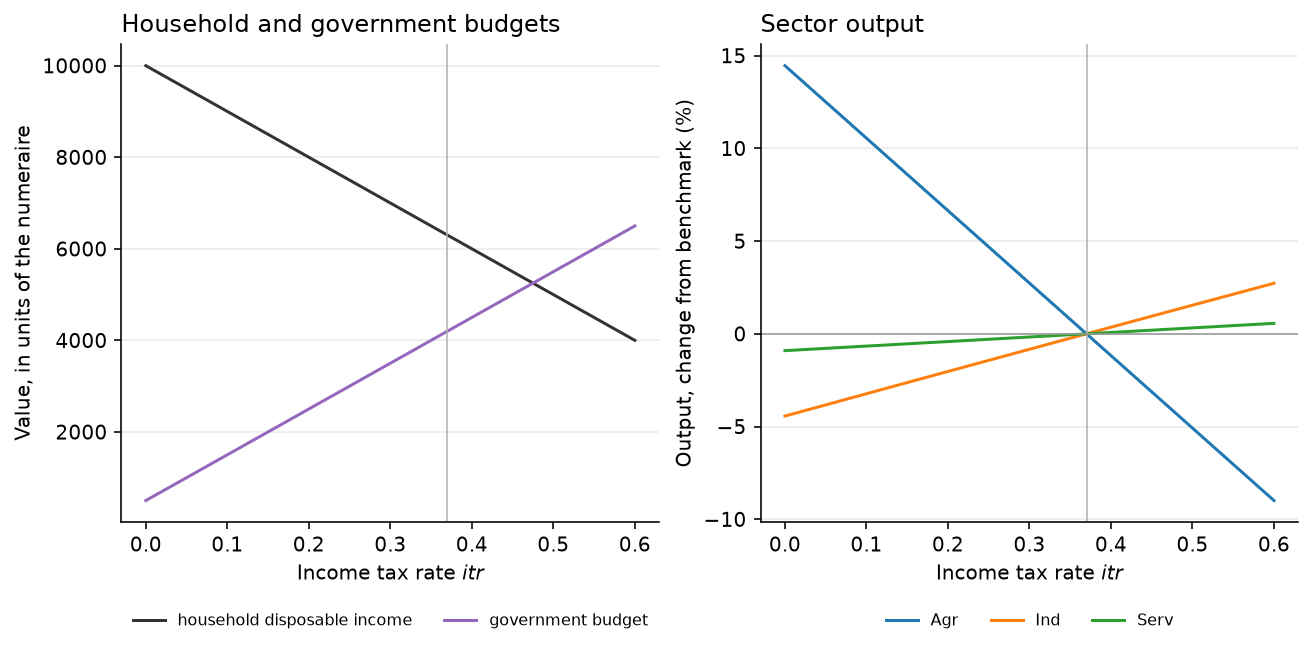

In [17]:
benchmark_output = calibrated_values["Y"]
budget_styles = {"DISP_INC": {"label": "household disposable income", "color": "0.2"},
                 "BUDG_EXP": {"label": "government budget", "color": "C4"}}

fig, (budget_ax, output_ax) = plt.subplots(ncols=2,
                                           figsize=(9, 4.4),
                                           dpi=144,
                                           sharex=True,
                                           layout="constrained")
for name, style in budget_styles.items():
    budget_ax.plot(tax_rate_sweep["itr"],
                   tax_rate_sweep[name],
                   **style)
for number, sector in enumerate(sectors):
    output_ax.plot(tax_rate_sweep["itr"],
                   100 * (tax_rate_sweep["Y"].sel(i=sector) / benchmark_output[number] - 1),
                   color=f"C{number}",
                   label=sector)

for ax in (budget_ax, output_ax):
    ax.axvline(benchmark_rate,
               color="0.7",
               linewidth=0.8)
    ax.grid(axis="y",
            color="0.92")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("Income tax rate $itr$")
    ax.legend(loc="upper center",
              bbox_to_anchor=(0.5, -0.16),
              ncol=len(ax.get_legend_handles_labels()[1]),
              frameon=False,
              fontsize=8)

budget_ax.set_ylabel("Value, in units of the numeraire")
budget_ax.set_title("Household and government budgets",
                    loc="left")
output_ax.axhline(0.0,
                  color="0.6",
                  linewidth=0.8)
output_ax.set_ylabel("Output, change from benchmark (%)")
output_ax.set_title("Sector output",
                    loc="left")
plt.show()

Disposable income and the government budget move almost one for one in opposite directions, because gross income hardly changes and indirect tax revenue is small. At a rate of 0 the government keeps only the indirect tax revenue, about 500. Sector output moves along nearly straight lines, with the slope set by the difference between the household and government shares of each good.

The exercise's 5 percentage point cut, to 0.32, moves the economy a little further along the same lines than the correction's cut to 0.333. The cell below solves it exactly.

In [18]:
exercise_cut = mod.simulate(initial_state=calibrated_values,
                            final_delta_pct={"itr": 0.32 / benchmark_rate},
                            progressbar=False)
assert exercise_cut["optim_res"].success

sector_growth(exercise_cut, names=["Y", "C", "P"]).round(3)

,Agr,Ind,Serv
Y growth (%),1.954,-0.595,-0.123
C growth (%),7.934,8.007,7.906
P growth (%),0.000,-0.067,0.026


## Authors

- Created by Jesse Grabowski, November 25, 2026

## Watermark

In [19]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Thu, 26 Nov 2026

Python implementation: CPython
Python version       : 3.12.13
IPython version      : 9.18.1

Compiler    : Clang 19.1.7 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

cge_modeling: 0.0.7.dev15+g93cb61e4e.d20261120
matplotlib  : 3.11.2
numpy       : 2.3.5
pandas      : 3.1.1

Watermark: 2.6.0

